# Nonlinear polariton freezing and condensation in a multimode Fabry-Perot cavity

**Authors: Xinwei Ji, Tao E. Li**

In this tutorial, we will try to understand how vibrational polaritons transport and condense inside a planar Fabry-Perot cavity. Specifically, we will adopt the **built-in GPU molecular dynamics drivers** inside MaxwellLink for these calculations (while external LAMMPS drivers are not needed).

This tutorial aims to deliver a few pieces of results in the following two papers:

1. Xinwei Ji, Tao E. Li. Nonlinear Freezing of Vibrational Polariton Transport via Mesoscale Simulations. [Nano Lett. 26 (38), 13012–13018 (2026).](https://doi.org/10.1021/acs.nanolett.6c03367)
2. Xinwei Ji, Tao E. Li. Atomistic Emergence of Vibrational Polariton Condensation. [arXiv:2610.41133 (2026).](https://arxiv.org/abs/2610.41133)

To reduce the computational cost, we will focus mostly on a 1D Fabry-Perot cavity. We expect a cusomer-grade NVIDIA graphics card (such as RTX 5070 Ti) for running this tutorial.

## 1. 1D nonlinear freezing of polariton transport

This section sets up a 1D Fabry-Perot model for studying the polariton transport discussed in the first paper. Here, a short laser pulse locally excites the cavity mirrors.

<div style="max-width: 320px;">

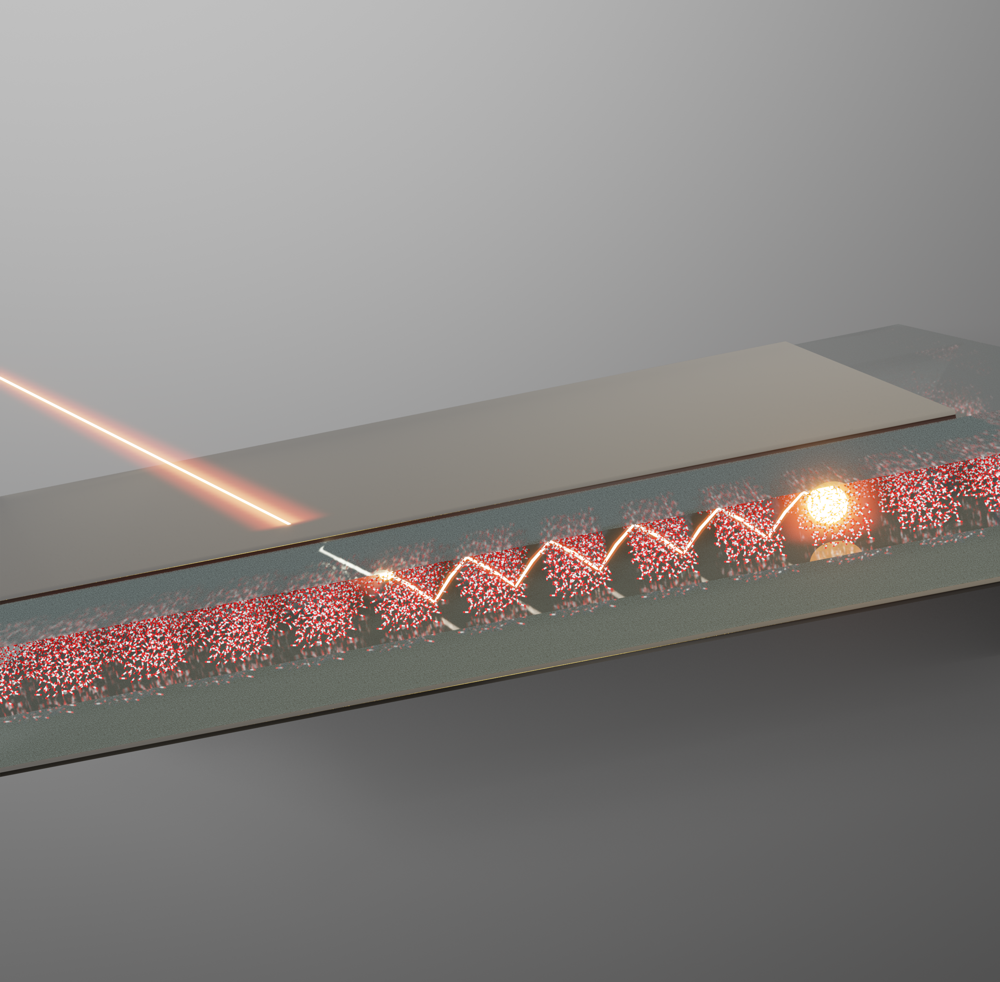

</div>

### 1.1. Initialize the cavity and molecular drivers

The light-matter model consists of 144 photon modes coupled to 144 molecular cells distributed along the `x`-axis. Each cell contains 36 CO2 molecules under periodic boundary conditions described by an anharmonic empirical force field (`co2jcp2021`). The cavity frequency at normal incidence is 2320 cm-1, at resonance with the asymmetric bending mode of CO2. Along the in-plane direction, we set the cavity mode frequency spacing to be 12.5 cm-1. We further adopt the absorbing boundary conditions along the cavity plane to avoid polariton reflection near the boundaries (with parameter `abc_cutoff=0.05`).

In our simulations, the multimode-cavity EM solver runs on CPU, whereas the heavy molecular dynamics are propagated on GPU. They connect with each other through the `AggregatedSocketHub` socket hub in MaxwellLink for communication. 

In [ ]:
import numpy as np
import maxwelllink as mxl

from maxwelllink.em_solvers.multimode_cavity import (
    FabryPerotCavity,
    MultiModeSimulation,
)
from maxwelllink.sockets import (
    AggregatedSocketHub,
    get_available_host_port,
)
from maxwelllink.tools import gaussian_pulse, k_parallel_pulse
from maxwelllink.tools.harmonic_oscillator_helper import (
    MaxwellBoltzmannInitializer,
    LangevinThermostat,
)
from maxwelllink.units import unit

N_grid_freezing = 144
coupling_strength_freezing = 2.5e-5
damping_au_freezing = 0e-4
dt_fs_freezing = 0.5

# define the Fabry-Perot cavity parameters
fbcavity_freezing = FabryPerotCavity(
    frequency_au=2320*unit("cm_inv"),
    coupling_strength=coupling_strength_freezing,
    coupling_axis="xy",
    n_grid_x=N_grid_freezing,
    y_grid_1d=[0.0],
    delta_omega_x_au=12.5*unit("cm_inv"),
    delta_omega_y_au=0.0*unit("cm_inv"),
    n_mode_x=N_grid_freezing,
    n_mode_y=1,
    abc_cutoff=0.05,
    save_mode_functions=True,
)
print(f"Coupling strength: {coupling_strength_freezing:.3e} au")

# Initialize the communication protocal
host_freezing, port_freezing = get_available_host_port(localhost=True)
hub_freezing = AggregatedSocketHub(host=host_freezing, port=port_freezing, timeout=6000.0, latency=1e-3)
print(f"SocketHub listening on {host_freezing}:{port_freezing}")

# Define the abstract Molecules. One socket-side molecule represents one complete MD cell
molecule_list_freezing = []
for _ in range(N_grid_freezing):
    molecule_list_freezing.append(
        mxl.Molecule(hub=hub_freezing, rescaling_factor=1.0, store_additional_data=False)
    )

# Set up the necessary parameters for the communication protocol
hub_freezing.init_remote_bridges(
    molecule_list_freezing,
    molecules_per_bridge=N_grid_freezing,
    unix_prefix="freezing_",
    save_file="aggregation_freezing.json",
)

[MultiModeCavity] omega_parallel in cm-1 [  12.5   25.    37.5   50.    62.5   75.    87.5  100.   112.5  125.
  137.5  150.   162.5  175.   187.5  200.   212.5  225.   237.5  250.
  262.5  275.   287.5  300.   312.5  325.   337.5  350.   362.5  375.
  387.5  400.   412.5  425.   437.5  450.   462.5  475.   487.5  500.
  512.5  525.   537.5  550.   562.5  575.   587.5  600.   612.5  625.
  637.5  650.   662.5  675.   687.5  700.   712.5  725.   737.5  750.
  762.5  775.   787.5  800.   812.5  825.   837.5  850.   862.5  875.
  887.5  900.   912.5  925.   937.5  950.   962.5  975.   987.5 1000.
 1012.5 1025.  1037.5 1050.  1062.5 1075.  1087.5 1100.  1112.5 1125.
 1137.5 1150.  1162.5 1175.  1187.5 1200.  1212.5 1225.  1237.5 1250.
 1262.5 1275.  1287.5 1300.  1312.5 1325.  1337.5 1350.  1362.5 1375.
 1387.5 1400.  1412.5 1425.  1437.5 1450.  1462.5 1475.  1487.5 1500.
 1512.5 1525.  1537.5 1550.  1562.5 1575.  1587.5 1600.  1612.5 1625.
 1637.5 1650.  1662.5 1675.  1687.5 1700.  1712.5

[RemoteBridgeSpec(idx=0, group_id='freezing_0', unixsocket='freezing_0', n_molecules=144)]

### 1.2. Define the laser pulse

The pulse drives the `y`-polarized photon field. Its spatial center is `x=0.2` (assuming the cavity plane spans [0, 1] in the units of cavity plane length `Lx`), with the spatial width set to 30% of the cavity plane length. The pulse frequency is set to 2438.84 cm-1, whereas the in-plane wave number of the pulse is 450 cm-1. This setting ensures that the pulse to excite the upper polariton branch near this in-plane wave number.

The pulse has a Gaussian envelope (centered at 0 fs and width 500 fs). During time 0 to 1000 fs, this pulse is turned on and then turned off afterwards.

In [2]:
pulse_envelope_freezing = gaussian_pulse(
    amplitude_au=1.0,
    t0_au=0*unit("fs"),
    sigma_au=5e2*unit("fs"),
    t_start_au=0.0*unit("fs"),
    t_end_au=1e3*unit("fs"),
)

photon_source_freezing = k_parallel_pulse(
    cavity=fbcavity_freezing,
    envelope=pulse_envelope_freezing,
    omega_au=2438.84*unit("cm_inv"),
    k_parallel_au=36*12.5*unit("cm_inv"),
    direction="x",
    center=(0.2, 0.0),
    size=(0.3, 1.0),
    target="photon",
    amplitude_au=0.007,
)

### 1.3. Define the multimode cavity coupled to molecules

Here, we define a multimode cavity EM solver on the CPU. This EM solver connects to the molecules via the `hub_freezing` socket protocal.

In [ ]:
rng_freezing = np.random.default_rng(seed=114514)
random_seed_freezing = rng_freezing.integers(1919810)

sim_freezing = MultiModeSimulation(
    hub=hub_freezing,
    molecules=molecule_list_freezing,
    dt_au=dt_fs_freezing*unit("fs"),
    damping_au=damping_au_freezing,
    include_dse=True,
    cavity_geometry=fbcavity_freezing,
    # here we assume that the pulse directly drives the cavity modes, which then couples to the molecules
    excited_mode_list=photon_source_freezing.excited_mode_list,
    photon_pulse_drive=photon_source_freezing,
    photon_pulse_axis="y",
    photon_partial_charge=0.066,
    # we set the cavity photons to obey a Maxwell-Boltzmann distribution at 300 K
    initializer=MaxwellBoltzmannInitializer(temperature_au=300.0*unit("K"), random_seed=random_seed_freezing),
    # always couple the cavity photon modes to a Langevin thermostat at 300 K, with a cavity loss lifetime of 5000 fs
    thermostat=LangevinThermostat(
        temperature_au=300.0*unit("K"),
        dt_au=dt_fs_freezing*unit("fs"),
        # cavity loss lifetime
        tau_au=5000*unit("fs"),
        random_seed=random_seed_freezing,
    ),
)

[LangevinThermostat] NVT thermostat enabled with T = 300.0 K = 0.0009500434689 a.u., Langevin tau = 5000.0 fs = 206706.866675 a.u.
[Maxwell-Boltzmann Initializer] Initializing positions with Maxwell-Boltzmann distribution at temperature 0.0009500434689 au.
[Maxwell-Boltzmann Initializer] Initializing momenta with Maxwell-Boltzmann distribution at temperature 0.0009500434689 au.


Now let's define the molecular drivers. The default setting in MaxwellLink uses either `mxl_driver` (for a few external drivers) or `mxl_bridge` (for a large number of drivers) to initialize the molecular drivers. We can run this command in a separate bash script. 

However, here in this notebook, we launch this bash command inside Python.

Note that this simulation will take about 4 minutes to finish on RTX 4090.

In [ ]:
import shlex
import subprocess

# we can directly run this command in a new separate terminal (this setting allows the EM to connect to a wide range of molecular drivers, as the EM is not aware of the specific molecular drivers).
# Here, each molecular driver runs on GPU (pre-equilibrated for 10 ps before coupling to the EM)
command_freezing = """
mxl_bridge --info aggregation_freezing.json --idx 0 \
    --backend gpu --model md \
    --param "ff=co2jcp2021,thermostat=nve,temperature_K=300.0,pre_nvt=True,pre_nvt_duration_ps=10.0,reset_dipole=True,seed=114514"
"""

# local Python process to direclty run this command in this notebook
bridge_process_freezing = subprocess.Popen(shlex.split(command_freezing))

try:
    print("Waiting for MD initialization and pre-NVT equilibration (if enabled)...", flush=True)
    sim_freezing._ensure_socket_connections()
    print("MD initialization and pre-NVT equilibration are complete. Starting the coupled simulation.", flush=True)

    # Run the coupled simulation directly
    sim_freezing.run(
        steps=20001,
        record_history=True,
        record_filename=None,
        record_every_steps=200,
        # save the E field dynamics during the simulations
        record_list=['effective_efield'],
    )
finally:
    hub_freezing.stop()
    bridge_process_freezing.wait()

Waiting for MD initialization and pre-NVT equilibration (if enabled)...
[SocketHub] CONNECTED: aggregate group 'freezing_0' <- 127.0.0.1:42396
MD initialization and pre-NVT equilibration are complete. Starting the coupled simulation.
[MultiModeCavity] Recording history: True, to disk: False, record_every_steps: 200, record_max_steps: 101
[MultiModeCavity] Recording fields : none
[MultiModeCavity] Recording address: N/A, filename: N/A
[MultiModeCavity] Temporary folder : N/A
[MultiModeCavity] Completed 1000/20001 [5.0%] steps, time/step: 6.04e-03 seconds, remaining time: 114.83 seconds.
[MultiModeCavity] Completed 2000/20001 [10.0%] steps, time/step: 5.88e-03 seconds, remaining time: 107.30 seconds.
[MultiModeCavity] Completed 3000/20001 [15.0%] steps, time/step: 5.97e-03 seconds, remaining time: 101.39 seconds.
[MultiModeCavity] Completed 4000/20001 [20.0%] steps, time/step: 5.98e-03 seconds, remaining time: 95.49 seconds.
[MultiModeCavity] Completed 5000/20001 [25.0%] steps, time/step

### 1.4. Plot the electric field

Now let's read `sim_freezing.effective_efield_history` to plot the EM field dynamics from the completed simulation.

Here, we see that after a while of polariton propagation, the EM field ceases to propagate and freezes. This is because the upper polariton at finite in-plane wave number transfers population to that at the polariton band edge (with almost zero group velocity).


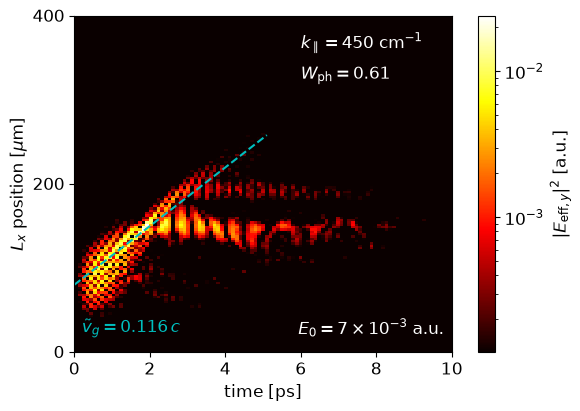

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LogNorm

# Select the y direction of the effective electric field from memory
sp_avg = (np.asarray(sim_freezing.effective_efield_history)[:, :, 1] ** 2).T
ntimes = sp_avg.shape[1]
time_ps_freezing = (
    1 + np.arange(ntimes) * sim_freezing.record_every_steps
) * sim_freezing.dt / unit("ps")
vmax = np.max(sp_avg)
vmin = vmax * 0.005

fig_freezing, ax_freezing = plt.subplots(figsize=(5.7, 4), layout="constrained")
pos = ax_freezing.imshow(
    sp_avg, aspect="auto", extent=[time_ps_freezing[0], time_ps_freezing[-1], 0, N_grid_freezing],
    origin="lower", cmap=cm.hot, interpolation="nearest",
    norm=LogNorm(vmin=vmin, vmax=vmax),
)

# the coeff is the analytical group velocity of this polariton in units of c (speed of light)
coeff = 0.11638023
t = time_ps_freezing[time_ps_freezing <= 5.2]
ax_freezing.plot(t, N_grid_freezing*0.2 + N_grid_freezing*0.75*coeff*t, "c--", lw=1.5)

ax_freezing.set_xlim(0, time_ps_freezing[-1])
ax_freezing.set_ylim(0, N_grid_freezing)
ax_freezing.set_yticks([0, N_grid_freezing / 2, N_grid_freezing])
ax_freezing.set_yticklabels([r"$0$", r"$200$", r"$400$"])
ax_freezing.set_xlabel("time [ps]", fontsize=12)
ax_freezing.set_ylabel(r"$L_x$ position [$\mu\mathrm{m}$]", fontsize=12)
ax_freezing.tick_params(labelsize=12)
ax_freezing.text(
    0.6, 0.95, r"$k_{\parallel}=450\ \mathrm{cm}^{-1}$",
    transform=ax_freezing.transAxes, fontsize=12, va="top", color="w",
)
ax_freezing.text(
    0.6, 0.85, r"$W_{\rm ph}=0.61$",
    transform=ax_freezing.transAxes, fontsize=12, va="top", color="w",
)
ax_freezing.text(
    0.98, 0.1, r"$E_0=7\times10^{-3}$ a.u.",
    transform=ax_freezing.transAxes, fontsize=12, va="top", ha="right", color="w",
)
ax_freezing.text(
    0.02, 0.1, r"$\tilde{v}_g=%.3f\,c$" % coeff,
    transform=ax_freezing.transAxes, fontsize=12, va="top", color="c",
)
cbar = fig_freezing.colorbar(pos, ax=ax_freezing, pad=0.04, fraction=0.055)
cbar.ax.tick_params(labelsize=12)
cbar.set_label(r"$|E_{\mathrm{eff},y}|^2$ [a.u.]", fontsize=12)
plt.show()


## 2. 1D polariton condensation

This section follows the second paper listed above, aiming to reproduce the vibrational polariton condensation in a 1D Fabry-Perot multimode cavity.

Here we send a strong continuous-wave (CW) pulse with a large wave `k`-vector to excite the central region of the system throughout the simulation (unlike the Gaussian pulse above).

<div style="max-width: 400px;">

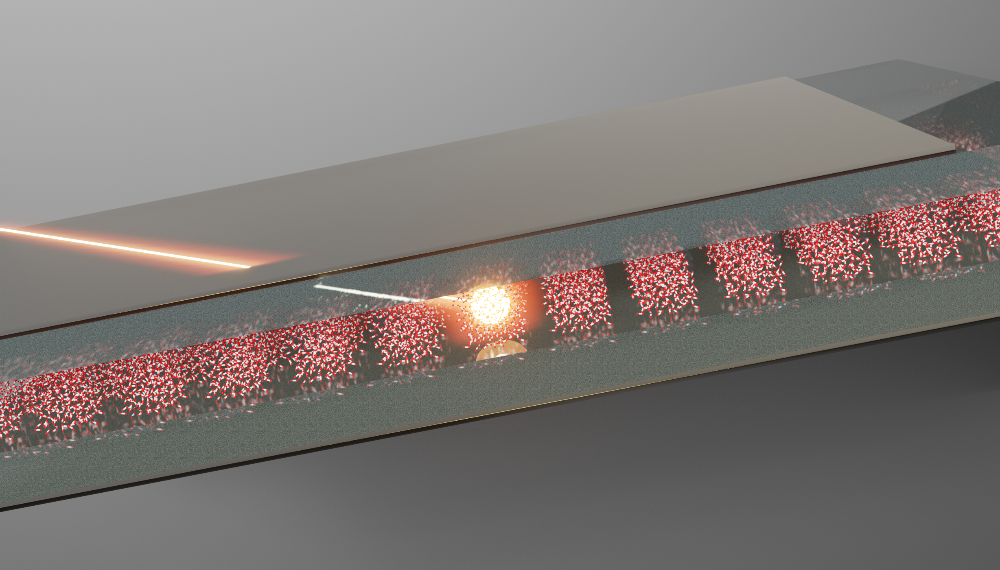

</div>

The same as above, the light-matter system consists of 144 photon modes coupled to 144 molecular cells, with 36 CO2 molecules in each cell. We tune the cavity frequency to `655 cm^-1`, at resonance with the asymmetric bending of CO2. (Note that in the above paper, the productive simulations used 720 cavity photon modes coupled to 720 molecular cells.)

### 2.1. Initialize the cavity and molecular drivers

We largely follow the above numerical settings.

In [ ]:
import numpy as np
import maxwelllink as mxl

from maxwelllink.em_solvers.multimode_cavity import (
    FabryPerotCavity,
    MultiModeSimulation,
)
from maxwelllink.sockets import (
    AggregatedSocketHub,
    get_available_host_port,
)
from maxwelllink.tools import k_parallel_pulse
from maxwelllink.tools.harmonic_oscillator_helper import (
    MaxwellBoltzmannInitializer,
    LangevinThermostat,
)
from maxwelllink.units import unit

fbcavity = FabryPerotCavity(
    frequency_au=655.0 * unit("cm_inv"),
    coupling_strength=1e-6 * np.sqrt(5),
    coupling_axis="xy",
    n_grid_x=144,
    y_grid_1d=[0.0],
    delta_omega_x_au=5.0 * unit("cm_inv"),
    delta_omega_y_au=0.0 * unit("cm_inv"),
    n_mode_x=144,
    n_mode_y=1,
    # we do not apply abosrbing boundary conditions here as no polariton propagation is observed
    abc_cutoff=0.0,
    save_mode_functions=True,
)

print(f"Coupling strength: {fbcavity.coupling_strength:.3e} au")

host, port = get_available_host_port(localhost=True)
hub = AggregatedSocketHub(host=host, port=port, timeout=6000.0, latency=1e-3)

molecule_list = []
for _ in range(fbcavity.n_grid):
    molecule_list.append(mxl.Molecule(hub=hub, rescaling_factor=1.0, store_additional_data=False))

hub.init_remote_bridges(
    molecule_list,
    molecules_per_bridge=fbcavity.n_grid,
    unix_prefix="bridge_",
    save_file="aggregation.json",
)

[MultiModeCavity] omega_parallel in cm-1 [  5.  10.  15.  20.  25.  30.  35.  40.  45.  50.  55.  60.  65.  70.
  75.  80.  85.  90.  95. 100. 105. 110. 115. 120. 125. 130. 135. 140.
 145. 150. 155. 160. 165. 170. 175. 180. 185. 190. 195. 200. 205. 210.
 215. 220. 225. 230. 235. 240. 245. 250. 255. 260. 265. 270. 275. 280.
 285. 290. 295. 300. 305. 310. 315. 320. 325. 330. 335. 340. 345. 350.
 355. 360. 365. 370. 375. 380. 385. 390. 395. 400. 405. 410. 415. 420.
 425. 430. 435. 440. 445. 450. 455. 460. 465. 470. 475. 480. 485. 490.
 495. 500. 505. 510. 515. 520. 525. 530. 535. 540. 545. 550. 555. 560.
 565. 570. 575. 580. 585. 590. 595. 600. 605. 610. 615. 620. 625. 630.
 635. 640. 645. 650. 655. 660. 665. 670. 675. 680. 685. 690. 695. 700.
 705. 710. 715. 720.]
[MultiModeCavity] omega_k in cm-1 [655.01908369 655.07633143 655.17173321 655.30527237 655.4769256
 655.68666297 655.93444794 656.22023742 656.54398177 656.90562488
 657.30510419 657.74235077 658.21728935 658.7298384  659.27991

[RemoteBridgeSpec(idx=0, group_id='bridge_0', unixsocket='bridge_0', n_molecules=144)]

### 2.2. Define the continuous-wave drive

We apply a spatially localized CW drive on the photon degrees of freedom. The CW pulse with wave number `144 * fbcavity.delta_omega_x_au=720 cm^{-1}` and  drive frequency `652.0 cm^{-1}`, corresponding to the highest LP mode along the dispersion curve, is attached to the central 30% region along the cavity plane.

In [7]:
photon_source = k_parallel_pulse(
    cavity=fbcavity,
    envelope=1.0,
    omega_au=652.0 * unit("cm_inv"),
    k_parallel_au=144 * fbcavity.delta_omega_x_au,
    direction="x",
    center=(0.5, 0.0),
    size=(0.3, 1.0),
    target="photon",
    amplitude_au=0.035,
)

### 2.3. Coupled light-matter dynamics

In [ ]:
rng = np.random.default_rng(seed=114514)
random_seed = int(rng.integers(1919810))

sim = MultiModeSimulation(
    hub=hub,
    molecules=molecule_list,
    dt_au=0.5 * unit("fs"),
    damping_au=0.0,
    include_dse=True,
    cavity_geometry=fbcavity,
    excited_mode_list=photon_source.excited_mode_list,
    photon_pulse_drive=photon_source,
    photon_pulse_axis="y",
    photon_partial_charge=0.066,
    initializer=MaxwellBoltzmannInitializer(
        temperature_au=300.0 * unit("K"),
        random_seed=random_seed,
    ),
    thermostat=LangevinThermostat(
        temperature_au=300.0 * unit("K"),
        dt_au=0.5 * unit("fs"),
        tau_au=5000.0 * unit("fs"),
        random_seed=random_seed,
    ),
)

[LangevinThermostat] NVT thermostat enabled with T = 300.0 K = 0.0009500434689 a.u., Langevin tau = 5000.0 fs = 206706.866675 a.u.
[Maxwell-Boltzmann Initializer] Initializing positions with Maxwell-Boltzmann distribution at temperature 0.0009500434689 au.
[Maxwell-Boltzmann Initializer] Initializing momenta with Maxwell-Boltzmann distribution at temperature 0.0009500434689 au.


In [9]:
import shlex
import subprocess

command = """
mxl_bridge --info aggregation.json --idx 0 \
    --backend gpu --model md \
    --param "ff=co2jcp2021,thermostat=nvt,friction_fs=5000.0,temperature_K=300.0,pre_nvt=True,pre_nvt_duration_ps=10.0,reset_dipole=True,seed=114514"
"""

bridge_process = subprocess.Popen(shlex.split(command))

try:
    sim._ensure_socket_connections()
    print("MD initialization complete. Starting the coupled simulation.", flush=True)
    sim.run(
        steps=80001,
        record_history=True,
        record_filename=None,
        record_every_steps=20,
        record_list=["qc", "photonic_energy_with_dse"],
    )
finally:
    hub.stop()
    bridge_process.wait()

[SocketHub] CONNECTED: aggregate group 'bridge_0' <- 127.0.0.1:59330
MD initialization complete. Starting the coupled simulation.
[MultiModeCavity] Recording history: True, to disk: False, record_every_steps: 20, record_max_steps: 4001
[MultiModeCavity] Recording fields : none
[MultiModeCavity] Recording address: N/A, filename: N/A
[MultiModeCavity] Temporary folder : N/A
[MultiModeCavity] Completed 1000/80001 [1.2%] steps, time/step: 5.93e-03 seconds, remaining time: 468.09 seconds.
[MultiModeCavity] Completed 2000/80001 [2.5%] steps, time/step: 5.92e-03 seconds, remaining time: 462.12 seconds.
[MultiModeCavity] Completed 3000/80001 [3.7%] steps, time/step: 5.93e-03 seconds, remaining time: 456.29 seconds.
[MultiModeCavity] Completed 4000/80001 [5.0%] steps, time/step: 5.92e-03 seconds, remaining time: 450.29 seconds.
[MultiModeCavity] Completed 5000/80001 [6.2%] steps, time/step: 5.91e-03 seconds, remaining time: 444.20 seconds.
[MultiModeCavity] Completed 6000/80001 [7.5%] steps, ti

## 3. Polariton spectrum and photon energy

Here, let's plot the nonequilibrium polariton spectrum and photonic energy dynamics from the memory.

Clearly, the LP band edge gains strong population during this nonequilibrium procedure, and the photonic energy dynamics also show that the photon modes at small in-plane wave numbers gain significant population. These results suggest the formation of **vibrational polariton condensation** from this mesoscale CavMD simulations.

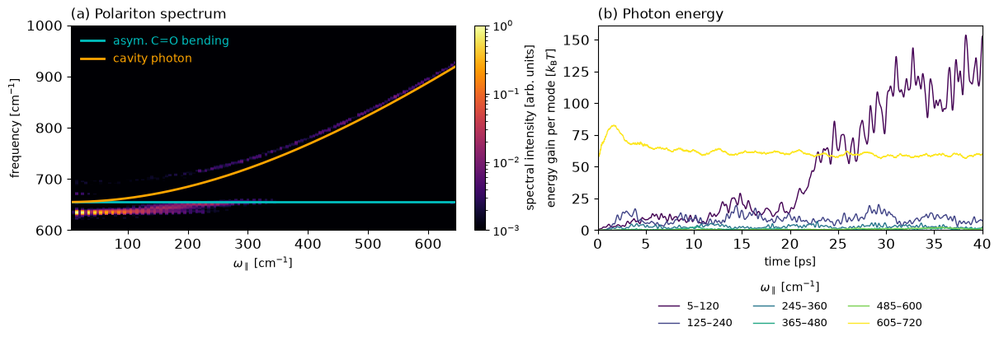

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib import cm
from maxwelllink.tools import ir_spectrum
from maxwelllink.tools.ir import smooth

# Plotting parameters
sample_dt_fs = sim.dt * sim.record_every_steps / unit("fs")
analysis_start_fs = 0.0
frequency_min_cm = 600.0
frequency_max_cm = 1000.0
molecular_frequency_cm = 655.0
first_mode_index = 1
relative_intensity_min = 1e-3
smooth_window_len = 11
modes_per_group = 24
energy_smooth_window_len = 21

# Select the y-polarized photon coordinates from memory
start_frame = int(np.ceil(analysis_start_fs / sample_dt_fs))
qc_y = np.asarray(sim.qc_history)[start_frame:, :, 1]

# Apply the same autocorrelation-based spectral helper as Tutorial 11
mode_spectra = []
for mode_index in range(qc_y.shape[1]):
    frequency_cm, spectrum = ir_spectrum(
        qc_y[:, mode_index],
        sample_dt_fs,
        smooth_window_len=smooth_window_len,
    )
    mode_spectra.append(spectrum)

spectrum_full = np.abs(np.column_stack(mode_spectra))
omega_parallel_cm = (
    np.arange(qc_y.shape[1]) + first_mode_index
) * (fbcavity.delta_omega_x_au / unit("cm_inv"))

frequency_mask = (
    (frequency_cm >= frequency_min_cm)
    & (frequency_cm <= frequency_max_cm)
)
plot_frequency_cm = frequency_cm[frequency_mask]
# Display only the first 90% of modes
n_plot_modes = int(0.9 * spectrum_full.shape[1])
plot_omega_parallel_cm = omega_parallel_cm[:n_plot_modes]
plot_spectrum = spectrum_full[frequency_mask, :n_plot_modes]

intensity_max = np.max(plot_spectrum)
if not np.isfinite(intensity_max) or intensity_max <= 0:
    raise ValueError("The selected frequency window has no finite, positive intensity.")
plot_spectrum = np.ma.masked_less_equal(plot_spectrum / intensity_max, 0.0)

fig, (ax, energy_ax) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
image = ax.pcolormesh(
    plot_omega_parallel_cm,
    plot_frequency_cm,
    plot_spectrum,
    shading="auto",
    cmap=cm.inferno,
    norm=LogNorm(vmin=relative_intensity_min, vmax=1.0),
)
cbar = fig.colorbar(image, ax=ax)
cbar.set_label("spectral intensity [arb. units]")

ax.axhline(
    molecular_frequency_cm,
    color="c",
    linewidth=2,
    label="asym. C=O bending",
)
ax.plot(
    plot_omega_parallel_cm,
    np.sqrt((fbcavity.frequency_au / unit("cm_inv"))**2 + plot_omega_parallel_cm**2),
    color="orange",
    linewidth=2,
    label="cavity photon",
)

ax.set_xlim(plot_omega_parallel_cm[0], plot_omega_parallel_cm[-1])
ax.set_ylim(frequency_min_cm, frequency_max_cm)
ax.set_xlabel(r"$\omega_{\parallel}$ [cm$^{-1}$]")
ax.set_ylabel(r"frequency [cm$^{-1}$]")
ax.tick_params(labelsize=12)
ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor="linecolor")

# Group all photon modes together
photonic_energy = np.asarray(sim.photonic_energy_with_dse_history)
grouped_energy = photonic_energy.reshape(
    photonic_energy.shape[0], -1, modes_per_group
).sum(axis=2)

time_ps = (
    1 + np.arange(grouped_energy.shape[0]) * sim.record_every_steps
) * sim.dt / unit("ps")

energy_scale = modes_per_group * sim.thermostat.temperature_au
energy_ys = [
    smooth(trace, energy_smooth_window_len) / energy_scale - 2
    for trace in grouped_energy.T
]

energy_labels = [
    f"{omega_parallel_cm[group_index * modes_per_group]:.0f}–"
    f"{omega_parallel_cm[(group_index + 1) * modes_per_group - 1]:.0f}"
    for group_index in range(grouped_energy.shape[1])
]

energy_ax.set_prop_cycle(
    color=cm.viridis(np.linspace(0, 1, grouped_energy.shape[1]))
)
for energy_trace, label in zip(energy_ys, energy_labels):
    energy_ax.plot(time_ps, energy_trace, label=label, linewidth=1.0)

energy_ax.set_xlim(0, time_ps[-1])
energy_ax.set_ylim(bottom=0)
energy_ax.set_xlabel("time [ps]")
energy_ax.set_ylabel(r"energy gain per mode [$k_{\mathrm{B}}T$]")
energy_ax.tick_params(labelsize=12)
energy_ax.legend(
    title=r"$\omega_{\parallel}$ [cm$^{-1}$]",
    ncols=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    fontsize=9,
    frameon=False,
)
ax.set_title("(a) Polariton spectrum", loc="left")
energy_ax.set_title("(b) Photon energy", loc="left")
plt.show()

## 4. 2D simulation for condensation dynamics

To conclude this tutorial, let's run a final 2D Fabry-Perot simulation to directly capture the condensation movie along the cavity mirror plane.

Here, we place the molecular cells on a 144 × 144=20,736 grid between the cavity mirrors. Each cell contains 36 CO2 molecules along the periodic boundary conditions.

To save some computation cost, we turn off the pre-equilibration `pre_nvt=False` (which should be turned on in production runs). This simulation will take about 17 minutes to finish on a single RTX 4090. 

We observe some rough fluid-like dynamics of the EM field. Note that for gaining high spectral resolution, the paper reports the runs with a 720x720 grid, which requires running for ~36 hours on a H100 GPU card.

In [ ]:
import numpy as np
import maxwelllink as mxl

from maxwelllink.em_solvers.multimode_cavity import (
    FabryPerotCavity,
    MultiModeSimulation,
)
from maxwelllink.sockets import (
    AggregatedSocketHub,
    get_available_host_port,
)
from maxwelllink.tools import k_parallel_pulse
from maxwelllink.tools.harmonic_oscillator_helper import (
    MaxwellBoltzmannInitializer,
    LangevinThermostat,
)
from maxwelllink.units import unit

rng_2d = np.random.default_rng(seed=114514)
random_seed_2d = int(rng_2d.integers(1919810))
N_grid_x = 144
N_grid_y = 144
N_grid = N_grid_x * N_grid_y
coupling_strength_2d = 1e-6 / np.sqrt(144*144/720)
damping_au_2d = 0e-4
dt_fs_2d = 0.5

fbcavity_2d = FabryPerotCavity(
    frequency_au=655*unit("cm_inv"),
    coupling_strength=coupling_strength_2d,
    coupling_axis="xy",
    n_grid_x=N_grid_x,
    n_grid_y=N_grid_y,
    delta_omega_x_au=5.0*unit("cm_inv"),
    delta_omega_y_au=5.0*unit("cm_inv"),
    n_mode_x=N_grid_x,
    n_mode_y=N_grid_y,
    save_mode_functions=False,
    mode_start_index_x=1,
    mode_start_index_y=0,
)
print(f"Coupling strength: {coupling_strength_2d:.3e} au")

# One socket-side molecule represents one complete MD cell
host_2d, port_2d = get_available_host_port(localhost=True)
hub_2d = AggregatedSocketHub(host=host_2d, port=port_2d, timeout=6000.0, latency=1e-3)
print(f"SocketHub listening on {host_2d}:{port_2d}")

molecule_list_2d = []
for _ in range(N_grid):
    molecule_list_2d.append(mxl.Molecule(hub=hub_2d, rescaling_factor=1.0, store_additional_data=False))

hub_2d.init_remote_bridges(
    molecule_list_2d,
    molecules_per_bridge=N_grid,
    unix_prefix="gpu0.002_",
    save_file="aggregation_2d.json",
)

# Apply a continuous photon drive to the center of the 2D cavity mirror plane
photon_source_2d = k_parallel_pulse(
    cavity=fbcavity_2d,
    envelope=1.0,
    omega_au=652*unit("cm_inv"),
    k_parallel_au=[720*unit("cm_inv"),0*unit("cm_inv")],
    direction="xy",
    center=(0.5, 0.5),
    size=(0.3, 0.3),
    target="photon",
    amplitude_au=0.064,
)

sim_2d = MultiModeSimulation(
    hub=hub_2d,
    molecules=molecule_list_2d,
    dt_au=dt_fs_2d*unit("fs"),
    damping_au=damping_au_2d,
    include_dse=True,
    cavity_geometry=fbcavity_2d,
    excited_mode_list=photon_source_2d.excited_mode_list,
    photon_pulse_drive=photon_source_2d,
    photon_pulse_axis="y",
    photon_partial_charge=0.43,
    initializer=MaxwellBoltzmannInitializer(temperature_au=300.0*unit("K"), random_seed=random_seed_2d),
    thermostat=LangevinThermostat(
        temperature_au=300.0*unit("K"),
        dt_au=dt_fs_2d*unit("fs"),
        tau_au=5000*unit("fs"),
        random_seed=random_seed_2d,
    ),
)

import shlex
import subprocess

command_2d = """
mxl_bridge --info aggregation_2d.json --idx 0 \
    --backend gpu --model md \
    --param "ff=co2jcp2021,thermostat=nvt,friction_fs=5000.0,temperature_K=300.0,pre_nvt=False,pre_nvt_duration_ps=10.0,reset_dipole=True,seed=114514"
"""

bridge_process_2d = subprocess.Popen(shlex.split(command_2d))

try:
    sim_2d._ensure_socket_connections()
    print("MD initialization complete. Starting the coupled simulation.", flush=True)
    sim_2d.run(
        steps=30001,
        record_history=True,
        record_filename=None,
        record_every_steps=300,
        record_list=["effective_efield"],
    )
finally:
    hub_2d.stop()
    bridge_process_2d.wait()


[MultiModeCavity] omega_parallel in cm-1 [   5.           10.           15.         ... 1007.63336586 1011.1626971
 1014.70439045]
[MultiModeCavity] omega_k in cm-1 [ 655.01908369  655.07633143  655.17173321 ... 1201.81113325 1204.77176262
 1207.74583419]
[MultiModeCavity] Applying Absorbing Boundary Condition: False, cutoff: [0.0, 0.0]
Coupling strength: 1.863e-07 au
SocketHub listening on 127.0.0.1:50339
[Init Molecule] Under socket mode, registered molecule with ID 0
[SocketHub] Prepared 1 remote aggregate bridge(s); manifest saved to 'aggregation_2d.json'.
[SocketHub] REMOTE BRIDGE 0: unix='gpu0.002_0' group='gpu0.002_0' molecules=20736
[LangevinThermostat] NVT thermostat enabled with T = 300.0 K = 0.0009500434689 a.u., Langevin tau = 5000.0 fs = 206706.866675 a.u.
[Maxwell-Boltzmann Initializer] Initializing positions with Maxwell-Boltzmann distribution at temperature 0.0009500434689 au.
[Maxwell-Boltzmann Initializer] Initializing momenta with Maxwell-Boltzmann distribution at te

## 5. Animate the y-polarized electric field

After the 2D simulation, we take the `y` component from `sim_2d.effective_efield_history` in memory and square it to show $|E_{\mathrm{eff},y}|^2$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LogNorm
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from maxwelllink.units import unit

# Use the completed 2D run and adjust the movie settings here
shape = (fbcavity_2d.n_grid_y, fbcavity_2d.n_grid_x)
fps = 25
dpi = 120
frame_interval_fs = 150
box_length_mm = 1.0
amplitude_label = r"$E_0=6.4 \times 10^{-2}$ a.u."
record_dt_fs = sim_2d.dt * sim_2d.record_every_steps / unit("fs")
frame_stride = max(1, int(round(frame_interval_fs / record_dt_fs)))

efield_data = sim_2d.effective_efield_history
frame_indices = np.arange(0, len(efield_data), frame_stride)

# Cartesian index 1 denotes y-direction
efield_vmax = max(
    float(np.max(efield_data[frame_id][:, 1] ** 2))
    for frame_id in frame_indices
)
if not np.isfinite(efield_vmax) or efield_vmax <= 0:
    raise ValueError("The selected y-field frames have no finite, positive intensity.")
norm = LogNorm(vmin=efield_vmax * 0.005, vmax=efield_vmax)

fig_efield, ax_efield = plt.subplots(figsize=(5.7, 4.8), dpi=dpi, layout="constrained")
image_efield = ax_efield.imshow(
    (efield_data[frame_indices[0]][:, 1] ** 2).reshape(shape),
    aspect="equal",
    extent=[0, box_length_mm, 0, box_length_mm],
    origin="lower",
    cmap=cm.hot,
    interpolation="nearest",
    norm=norm,
)
ax_efield.set_box_aspect(1)
ax_efield.set_xlabel("x position [mm]", fontsize=12)
ax_efield.set_ylabel("y position [mm]", fontsize=12)
ax_efield.set_xticks([0, box_length_mm / 2, box_length_mm])
ax_efield.set_yticks([0, box_length_mm / 2, box_length_mm])
ax_efield.tick_params(labelsize=12)
ax_efield.text(
    0.98, 0.98, "CO₂ bending", transform=ax_efield.transAxes,
    fontsize=12, fontweight="bold", va="top", ha="right", color="w",
)
time_text = ax_efield.text(
    0.98, 0.18, "", transform=ax_efield.transAxes,
    fontsize=12, fontweight="bold", va="top", ha="right", color="w",
)
ax_efield.text(
    0.98, 0.08, amplitude_label, transform=ax_efield.transAxes,
    fontsize=12, fontweight="bold", va="top", ha="right", color="w",
)
colorbar = fig_efield.colorbar(image_efield, ax=ax_efield, pad=0.04, fraction=0.046)
colorbar.ax.tick_params(labelsize=12)
colorbar.set_label(r"$|E_{\mathrm{eff},y}|^2$ [a.u.]", fontsize=12)

def update_frame(frame_id):
    image_efield.set_data((efield_data[frame_id][:, 1] ** 2).reshape(shape))
    time_ps = (1 + frame_id * sim_2d.record_every_steps) * sim_2d.dt / unit("ps")
    time_text.set_text(r"$t=%.2f$ ps" % time_ps)
    return image_efield, time_text

movie = FuncAnimation(
    fig_efield, update_frame, frames=frame_indices,
    interval=1000 / fps, blit=False,
)

with plt.rc_context({"animation.embed_limit": float("inf")}):
    animation_html = movie.to_jshtml(fps=fps, embed_frames=True)
plt.close(fig_efield)
display(HTML(animation_html.replace(
    "<img ", '<img style="max-width: 480px; height: auto;" ', 1
)))
